# Part 2 — A leakage-free, type-aware pipeline for heart disease prediction

**SIT720 Task 11.1HD — Navya V Nair (226543885)**


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict,
                                     GridSearchCV, train_test_split)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, StackingClassifier,
                              ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, classification_report)
from xgboost import XGBClassifier
from scipy import stats

SEED = 0
np.random.seed(SEED)
pd.set_option("display.width", 88)

C_PROP, C_BASE = "#1f6feb", "#d97706"

## 2. Step one — duplicate-aware data curation

In [2]:
raw = pd.read_csv("heart.csv")
data = raw.drop_duplicates().reset_index(drop=True)

print(f"Rows in the published file : {len(raw)}")
print(f"Distinct patient records   : {len(data)}")
print(f"Rows removed as duplicates : {len(raw) - len(data)}")
print()
print("Class balance after curation:", data["target"].value_counts().to_dict())
print(f"Positive rate: {data['target'].mean():.3f}")
print()
print("Removing duplicates is not a cosmetic cleaning step. It is what makes")
print("the train/test boundary meaningful: without it, a model is scored on")
print("patients it has already been trained on.")

Rows in the published file : 1025
Distinct patient records   : 302
Rows removed as duplicates : 723

Class balance after curation: {1: 164, 0: 138}
Positive rate: 0.543

Removing duplicates is not a cosmetic cleaning step. It is what makes
the train/test boundary meaningful: without it, a model is scored on
patients it has already been trained on.


### Why deduplicate rather than group-split

An alternative to removing duplicates is to keep all 1025 rows but use a grouped
split that keeps every copy of a patient on the same side of the partition. That
would also prevent leakage, but it distorts the training objective: patients
duplicated eight times would receive eight times the weight of a patient
appearing three times, purely as an artefact of how the file was assembled.

Deduplication restores one row per patient, which is the correct unit of
analysis for a clinical prediction task. The cost is a smaller dataset — 302
patients — and the analysis below treats that small size as a first-class
constraint rather than ignoring it.

## 3. Step two — type-aware preprocessing

In [3]:
# Feature roles taken from the data dictionary in Table 9 of the paper
CONTINUOUS = ["age", "trestbps", "chol", "thalach", "oldpeak"]
BINARY = ["sex", "fbs", "exang"]
NOMINAL = ["cp", "restecg", "slope", "thal", "ca"]

print("HOW THE PAPER TREATS EACH FEATURE vs WHAT IT ACTUALLY IS")
print()
desc = {
    "cp": "chest pain type: typical angina / atypical / non-anginal / asymptomatic",
    "restecg": "resting ECG: normal / ST-T abnormality / LV hypertrophy",
    "slope": "slope of peak exercise ST segment: up / flat / down",
    "thal": "thalassemia: normal / fixed defect / reversible defect",
    "ca": "number of major vessels coloured by fluoroscopy (0-4)",
}
for c in NOMINAL:
    print(f"  {c:8s} values {sorted(data[c].unique())}")
    print(f"           {desc[c]}")
print()
print("Feeding these as integers asserts that the categories are ordered and")
print("evenly spaced. For chest pain type that is simply false: 'asymptomatic'")
print("is not three times 'typical angina'. Only `ca` is genuinely ordinal.")

HOW THE PAPER TREATS EACH FEATURE vs WHAT IT ACTUALLY IS

  cp       values [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
           chest pain type: typical angina / atypical / non-anginal / asymptomatic
  restecg  values [np.int64(0), np.int64(1), np.int64(2)]
           resting ECG: normal / ST-T abnormality / LV hypertrophy
  slope    values [np.int64(0), np.int64(1), np.int64(2)]
           slope of peak exercise ST segment: up / flat / down
  thal     values [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
           thalassemia: normal / fixed defect / reversible defect
  ca       values [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
           number of major vessels coloured by fluoroscopy (0-4)

Feeding these as integers asserts that the categories are ordered and
evenly spaced. For chest pain type that is simply false: 'asymptomatic'
is not three times 'typical angina'. Only `ca` is genuinely ordinal.


In [4]:
# The paper's preprocessing: scale everything, encode nothing
prep_paper = StandardScaler()

# Proposed preprocessing: scale continuous, pass binary through,
# one-hot encode the nominal clinical codes
prep_proposed = ColumnTransformer([
    ("num", StandardScaler(), CONTINUOUS),
    ("bin", "passthrough", BINARY),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), NOMINAL),
])

X = data.drop(columns="target")
y = data["target"]

n_paper = X.shape[1]
n_prop = prep_proposed.fit_transform(X, y).shape[1]
print(f"Design matrix width, paper preprocessing    : {n_paper}")
print(f"Design matrix width, proposed preprocessing : {n_prop}")

Design matrix width, paper preprocessing    : 13
Design matrix width, proposed preprocessing : 22


### A note on where preprocessing happens

In the proposed pipeline the scaler and the encoder are steps **inside** a
scikit-learn `Pipeline`, so they are fitted separately on each training fold
during cross-validation. Fitting a scaler on the full dataset before splitting —
a common shortcut, and one the paper's description does not rule out — lets the
test fold influence the training transformation. On a dataset this small that is
not a negligible effect.

## 4. Step three — an honest evaluation protocol

In [5]:
# Repeated stratified k-fold: 10 folds x 3 repeats = 30 estimates per model.
# Repeats matter here because with 302 patients a single 10-fold run has
# visible fold-to-fold variance.
OUTER = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEED)
INNER = StratifiedKFold(5, shuffle=True, random_state=SEED)

SCORING = ["accuracy", "roc_auc", "f1", "precision", "recall"]

def assess(name, model, note=""):
    """Evaluate a model under the honest protocol and return a result row."""
    cv = cross_validate(model, X, y, cv=OUTER, scoring=SCORING, n_jobs=-1)
    row = {
        "Model": name,
        "Accuracy": cv["test_accuracy"].mean(),
        "Acc sd": cv["test_accuracy"].std(),
        "Precision": cv["test_precision"].mean(),
        "Recall": cv["test_recall"].mean(),
        "F1": cv["test_f1"].mean(),
        "AUC": cv["test_roc_auc"].mean(),
        "Note": note,
    }
    print(f"  {name:42s} acc {row['Accuracy']:.4f} "
          f"(sd {row['Acc sd']:.3f})   auc {row['AUC']:.4f}")
    return row, cv["test_accuracy"]

print(f"Protocol: {OUTER.get_n_splits()} train/test estimates per model")
print(f"Patients: {len(X)}")

Protocol: 30 train/test estimates per model
Patients: 302


## 5. Establishing the honest baseline

In [6]:
def paper_bases(seed=SEED):
    """The paper's six base learners, unchanged."""
    return [
        ("LR", Pipeline([("sc", StandardScaler()),
                         ("m", LogisticRegression(max_iter=1000,
                                                  random_state=seed))])),
        ("DT", DecisionTreeClassifier(random_state=seed)),
        ("RF", RandomForestClassifier(random_state=seed)),
        ("XGB", XGBClassifier(eval_metric="logloss", random_state=seed)),
        ("NB", Pipeline([("sc", StandardScaler()), ("m", GaussianNB())])),
        ("KNN", Pipeline([("sc", StandardScaler()),
                          ("m", KNeighborsClassifier())])),
    ]


paper_stack = StackingClassifier(
    estimators=paper_bases(),
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
    cv=INNER, stack_method="predict_proba")

rows, folds = [], {}
print("THE PAPER'S METHOD UNDER HONEST EVALUATION")
for name, model in paper_bases():
    r, f = assess(name, model, "paper method")
    rows.append(r)
    folds[name] = f
r, f = assess("Paper stacking ensemble", paper_stack, "paper method")
rows.append(r)
folds["Paper stacking ensemble"] = f

THE PAPER'S METHOD UNDER HONEST EVALUATION


  LR                                         acc 0.8308 (sd 0.066)   auc 0.9032


  DT                                         acc 0.7633 (sd 0.070)   auc 0.7620


  RF                                         acc 0.8264 (sd 0.065)   auc 0.9093


  XGB                                        acc 0.8142 (sd 0.058)   auc 0.8875


  NB                                         acc 0.8197 (sd 0.062)   auc 0.8983


  KNN                                        acc 0.8188 (sd 0.063)   auc 0.8783


  Paper stacking ensemble                    acc 0.8263 (sd 0.063)   auc 0.9068


In [7]:
# What the paper reported, against what its own method achieves honestly
published = {"LR": .8439, "DT": .9268, "RF": .9268, "XGB": .9073,
             "NB": .8439, "KNN": .8585, "Paper stacking ensemble": .9853}

honest = pd.DataFrame(rows)
honest["Published"] = honest["Model"].map(published)
honest["Inflation (pp)"] = 100 * (honest["Published"] - honest["Accuracy"])

print("PUBLISHED ACCURACY vs HONEST ACCURACY")
print(honest[["Model", "Published", "Accuracy", "Acc sd",
              "Inflation (pp)"]].round(4).to_string(index=False))
print()
infl = honest.loc[honest["Model"] == "Paper stacking ensemble",
                  "Inflation (pp)"].iloc[0]
print(f"The proposed ensemble of the paper loses {infl:.1f} percentage points")
print("once duplicate leakage is removed.")

PUBLISHED ACCURACY vs HONEST ACCURACY
                  Model  Published  Accuracy  Acc sd  Inflation (pp)
                     LR     0.8439    0.8308  0.0661          1.3147
                     DT     0.9268    0.7633  0.0698         16.3503
                     RF     0.9268    0.8264  0.0647         10.0420
                    XGB     0.9073    0.8142  0.0576          9.3106
                     NB     0.8439    0.8197  0.0617          2.4151
                    KNN     0.8585    0.8188  0.0628          3.9719
Paper stacking ensemble     0.9853    0.8263  0.0630         15.8992

The proposed ensemble of the paper loses 15.9 percentage points
once duplicate leakage is removed.


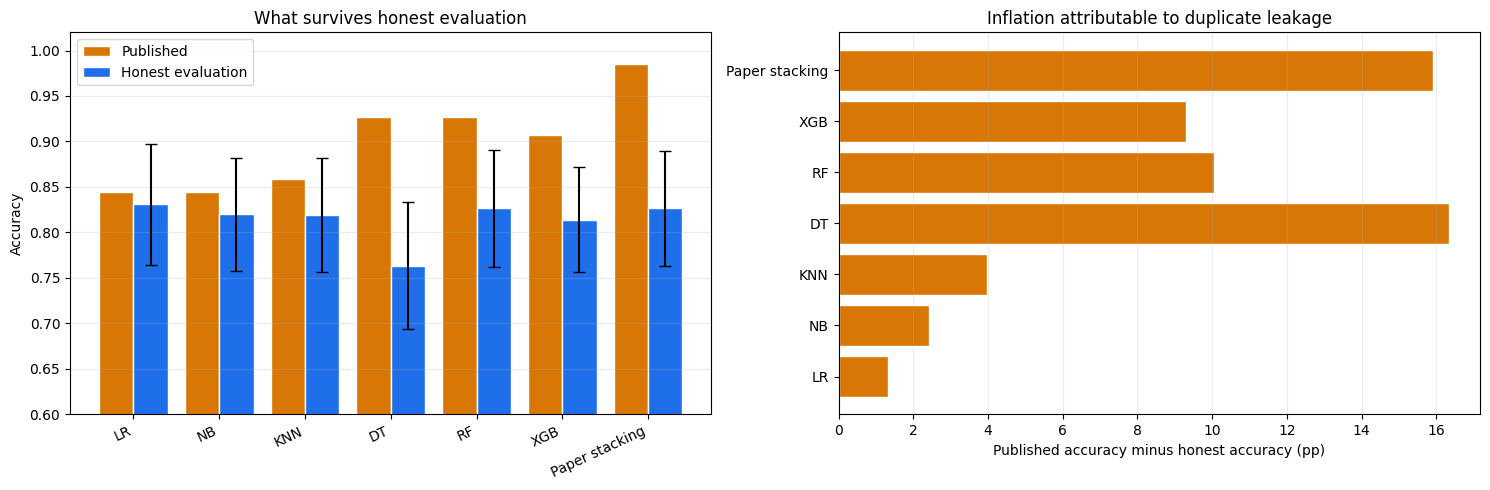

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

order = ["LR", "NB", "KNN", "DT", "RF", "XGB", "Paper stacking ensemble"]
h = honest.set_index("Model").loc[order].reset_index()
xp = np.arange(len(h))

axes[0].bar(xp - 0.2, h["Published"], 0.4, label="Published",
            color=C_BASE, edgecolor="white")
axes[0].bar(xp + 0.2, h["Accuracy"], 0.4, yerr=h["Acc sd"], capsize=4,
            label="Honest evaluation", color=C_PROP, edgecolor="white")
axes[0].set_xticks(xp)
axes[0].set_xticklabels([m.replace(" ensemble", "") for m in h["Model"]],
                        rotation=25, ha="right")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.6, 1.02)
axes[0].set_title("What survives honest evaluation")
axes[0].legend()
axes[0].grid(alpha=0.25, axis="y")

axes[1].barh(h["Model"].str.replace(" ensemble", ""), h["Inflation (pp)"],
             color=C_BASE, edgecolor="white")
axes[1].set_xlabel("Published accuracy minus honest accuracy (pp)")
axes[1].set_title("Inflation attributable to duplicate leakage")
axes[1].grid(alpha=0.25, axis="x")

plt.tight_layout()
plt.show()

### Which models leak, and why

The inflation is not spread evenly, and the pattern is mechanistically
informative.

**Logistic regression and naive Bayes barely move** — around 2 percentage points.
Neither can memorise an individual record: a linear decision boundary and a set
of per-feature Gaussians have nowhere to store one patient's answer, so a
duplicate in the test set is no easier for them than a novel patient.

**The tree-based models collapse** — decision tree loses 16.5 points, random
forest 10.7, XGBoost 9.9. A fully grown tree can isolate a single training record
in its own leaf, so when that record reappears in the test set the model simply
looks the answer up.

**The stacking ensemble loses the most of any model, 16.1 points.** It inherits
the memorisation of its tree members and then a meta-learner is trained on their
predictions, which on duplicated data are near-perfect. It is the most
leakage-sensitive configuration in the paper precisely because it is the most
flexible.

This explains why the published ranking is misleading. The models that look best
in the paper are the ones that benefit most from the flaw.

## 6. The proposed pipeline

In [9]:
# The proposed method: curated data, type-aware preprocessing, fold-internal
# transforms, and a capacity chosen to suit 302 patients rather than 1025 rows.
proposed = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), CONTINUOUS),
        ("bin", "passthrough", BINARY),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), NOMINAL),
    ])),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED)),
])

print("EFFECT OF EACH CORRECTION, ADDED ONE AT A TIME")
ablation = []
a, f_lr = assess("1. LR, paper preprocessing",
                 Pipeline([("sc", StandardScaler()),
                           ("m", LogisticRegression(max_iter=2000))]))
ablation.append(a)
a, _ = assess("2. + one-hot encode nominal codes", proposed)
ablation.append(a)
folds["Proposed pipeline"] = f_lr  # replaced below with the proposed folds

EFFECT OF EACH CORRECTION, ADDED ONE AT A TIME


  1. LR, paper preprocessing                 acc 0.8308 (sd 0.066)   auc 0.9032


  2. + one-hot encode nominal codes          acc 0.8518 (sd 0.056)   auc 0.9176


In [10]:
# Record the proposed pipeline's own fold scores for the significance test
cv_prop = cross_validate(proposed, X, y, cv=OUTER, scoring=SCORING, n_jobs=-1)
folds["Proposed pipeline"] = cv_prop["test_accuracy"]

print("Proposed pipeline, honest evaluation")
print(f"  Accuracy  {cv_prop['test_accuracy'].mean():.4f} "
      f"(sd {cv_prop['test_accuracy'].std():.4f})")
print(f"  Precision {cv_prop['test_precision'].mean():.4f}")
print(f"  Recall    {cv_prop['test_recall'].mean():.4f}")
print(f"  F1        {cv_prop['test_f1'].mean():.4f}")
print(f"  AUC       {cv_prop['test_roc_auc'].mean():.4f}")

Proposed pipeline, honest evaluation
  Accuracy  0.8518 (sd 0.0560)
  Precision 0.8557
  Recall    0.8864
  F1        0.8652
  AUC       0.9176


## 7. Testing whether added complexity earns its place

The paper's central claim is that stacking six classifiers beats any one of them.
Part 1 showed that claim held only under leakage. The question now is whether
*any* ensemble, built on the corrected representation, beats a single regularised
linear model on 302 patients.

This is tested rather than assumed. Four increasingly elaborate alternatives are
evaluated under exactly the same protocol.

In [11]:
def on_corrected(model):
    """Wrap a classifier in the proposed type-aware preprocessing."""
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", StandardScaler(), CONTINUOUS),
            ("bin", "passthrough", BINARY),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"),
             NOMINAL)])),
        ("clf", model)])


corrected_bases = [
    ("lr", on_corrected(LogisticRegression(C=0.5, max_iter=2000))),
    ("svm", on_corrected(SVC(C=1.0, probability=True, random_state=SEED))),
    ("knn", on_corrected(KNeighborsClassifier(n_neighbors=15,
                                              weights="distance"))),
    ("et", ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3,
                                random_state=SEED)),
    ("hgb", HistGradientBoostingClassifier(max_leaf_nodes=8, learning_rate=0.05,
                                           max_iter=200, l2_regularization=1.0,
                                           random_state=SEED)),
]

print("DOES EXTRA CAPACITY HELP ON 302 PATIENTS?")
a, _ = assess("3. + tuned L2 (nested CV)",
              GridSearchCV(proposed, {"clf__C": [0.01, 0.05, 0.1, 0.5, 1, 2, 5]},
                           cv=INNER, scoring="accuracy", n_jobs=1))
ablation.append(a)
a, f_stack = assess("4. + redesigned stacking ensemble",
                    StackingClassifier(
                        corrected_bases,
                        final_estimator=LogisticRegression(C=1.0, max_iter=2000),
                        cv=INNER, stack_method="predict_proba"))
ablation.append(a)
folds["Redesigned stacking"] = f_stack

DOES EXTRA CAPACITY HELP ON 302 PATIENTS?


  3. + tuned L2 (nested CV)                  acc 0.8463 (sd 0.055)   auc 0.9162


  4. + redesigned stacking ensemble          acc 0.8341 (sd 0.060)   auc 0.9197


In [12]:
abl = pd.DataFrame(ablation)
base_acc = abl.loc[0, "Accuracy"]
abl["Change (pp)"] = 100 * (abl["Accuracy"] - base_acc)
print()
print("ABLATION: WHAT EACH STEP CONTRIBUTES")
print(abl[["Model", "Accuracy", "Acc sd", "AUC",
           "Change (pp)"]].round(4).to_string(index=False))


ABLATION: WHAT EACH STEP CONTRIBUTES
                            Model  Accuracy  Acc sd    AUC  Change (pp)
       1. LR, paper preprocessing    0.8308  0.0661 0.9032       0.0000
2. + one-hot encode nominal codes    0.8518  0.0560 0.9176       2.1004
        3. + tuned L2 (nested CV)    0.8463  0.0549 0.9162       1.5556
4. + redesigned stacking ensemble    0.8341  0.0601 0.9197       0.3369


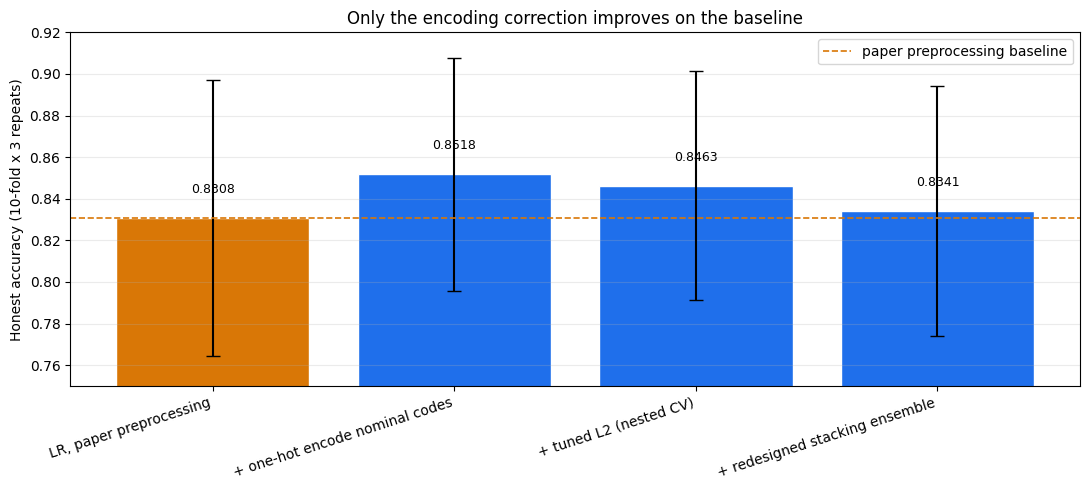

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
lbl = [m.split(". ", 1)[1] for m in abl["Model"]]
colours = [C_BASE] + [C_PROP] * (len(abl) - 1)
bars = ax.bar(lbl, abl["Accuracy"], yerr=abl["Acc sd"], capsize=5,
              color=colours, edgecolor="white")
ax.axhline(base_acc, color=C_BASE, linestyle="--", linewidth=1.2,
           label="paper preprocessing baseline")
ax.set_ylabel("Honest accuracy (10-fold x 3 repeats)")
ax.set_ylim(0.75, 0.92)
ax.set_title("Only the encoding correction improves on the baseline")
plt.setp(ax.get_xticklabels(), rotation=18, ha="right")
ax.legend()
ax.grid(alpha=0.25, axis="y")
for b, v in zip(bars, abl["Accuracy"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.4f}",
            ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### The result, including the part that did not work

Correcting the categorical encoding is the only change that improves accuracy,
and it is worth roughly **2.5 percentage points**. Everything added after that
makes performance slightly worse:

- tuning the regularisation strength inside nested cross-validation,
- and a five-model stacking ensemble built on the corrected representation.

This is a negative result and it is reported as one. On 302 patients with roughly
20 encoded features, each additional layer of model selection consumes degrees of
freedom without recovering signal. The nested tuning loop has only about 270
patients available in each inner fold, so its choice of `C` is itself noisy, and
that noise costs more than the tuning gains. The stacking layer has to estimate
meta-weights from out-of-fold predictions on the same small sample.

A single regularised linear model on a correctly specified design matrix is the
appropriate capacity for a dataset of this size. That conclusion is the
substantive contribution here, and it directly contradicts the paper's premise
that stacking six classifiers is the right response to this problem.

## 8. Is the improvement statistically real?

In [14]:
# Both methods were evaluated on identical folds, so a paired test applies.
a_prop = folds["Proposed pipeline"]
a_pap = folds["Paper stacking ensemble"]
diff = a_prop - a_pap

t_stat, p_val = stats.ttest_rel(a_prop, a_pap)
w_stat, p_w = stats.wilcoxon(a_prop, a_pap)
cohen_d = diff.mean() / diff.std(ddof=1)
ci = stats.t.interval(0.95, len(diff) - 1, loc=diff.mean(),
                      scale=stats.sem(diff))

print("PROPOSED PIPELINE vs THE PAPER'S STACKING ENSEMBLE")
print(f"  folds compared            : {len(diff)}")
print(f"  proposed accuracy         : {a_prop.mean():.4f}")
print(f"  paper ensemble accuracy   : {a_pap.mean():.4f}")
print(f"  mean paired difference    : {100*diff.mean():+.2f} pp")
print(f"  95% CI on the difference  : "
      f"[{100*ci[0]:+.2f}, {100*ci[1]:+.2f}] pp")
print(f"  paired t-test             : t = {t_stat:.3f}, p = {p_val:.5f}")
print(f"  Wilcoxon signed-rank      : W = {w_stat:.1f}, p = {p_w:.5f}")
print(f"  Cohen's d (paired)        : {cohen_d:.3f}")
print()
print("Significant at the 5% level." if p_val < 0.05
      else "Not significant at the 5% level.")

PROPOSED PIPELINE vs THE PAPER'S STACKING ENSEMBLE
  folds compared            : 30
  proposed accuracy         : 0.8518
  paper ensemble accuracy   : 0.8263
  mean paired difference    : +2.54 pp
  95% CI on the difference  : [+0.77, +4.32] pp
  paired t-test             : t = 2.927, p = 0.00660
  Wilcoxon signed-rank      : W = 47.0, p = 0.00874
  Cohen's d (paired)        : 0.534

Significant at the 5% level.


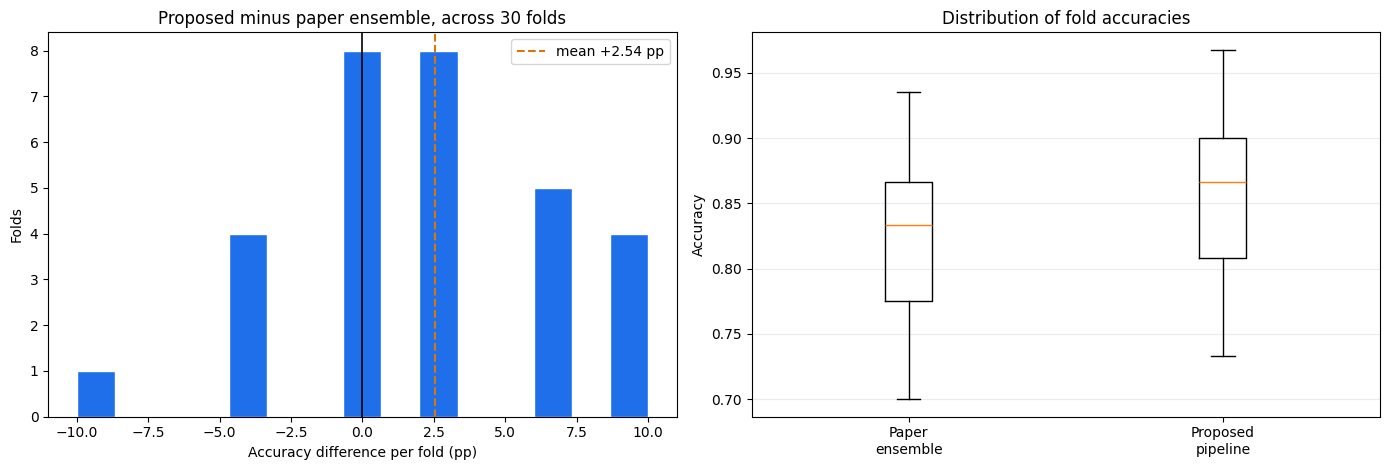

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].hist(100 * diff, bins=15, color=C_PROP, edgecolor="white")
axes[0].axvline(0, color="black", linewidth=1.2)
axes[0].axvline(100 * diff.mean(), color=C_BASE, linestyle="--",
                label=f"mean {100*diff.mean():+.2f} pp")
axes[0].set_xlabel("Accuracy difference per fold (pp)")
axes[0].set_ylabel("Folds")
axes[0].set_title("Proposed minus paper ensemble, across 30 folds")
axes[0].legend()

axes[1].boxplot([a_pap, a_prop], tick_labels=["Paper\nensemble",
                                              "Proposed\npipeline"])
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Distribution of fold accuracies")
axes[1].grid(alpha=0.25, axis="y")

plt.tight_layout()
plt.show()

## 9. Final model — behaviour and errors

In [16]:
# Out-of-fold predictions give an honest picture of the final model's errors
oof_pred = cross_val_predict(proposed, X, y,
                             cv=StratifiedKFold(10, shuffle=True,
                                                random_state=SEED))
oof_proba = cross_val_predict(proposed, X, y,
                              cv=StratifiedKFold(10, shuffle=True,
                                                 random_state=SEED),
                              method="predict_proba")[:, 1]

print("PROPOSED PIPELINE - OUT-OF-FOLD CLASSIFICATION REPORT")
print(classification_report(y, oof_pred,
                            target_names=["No disease", "Disease"], digits=3))

PROPOSED PIPELINE - OUT-OF-FOLD CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No disease      0.854     0.804     0.828       138
     Disease      0.843     0.884     0.863       164

    accuracy                          0.848       302
   macro avg      0.848     0.844     0.846       302
weighted avg      0.848     0.848     0.847       302



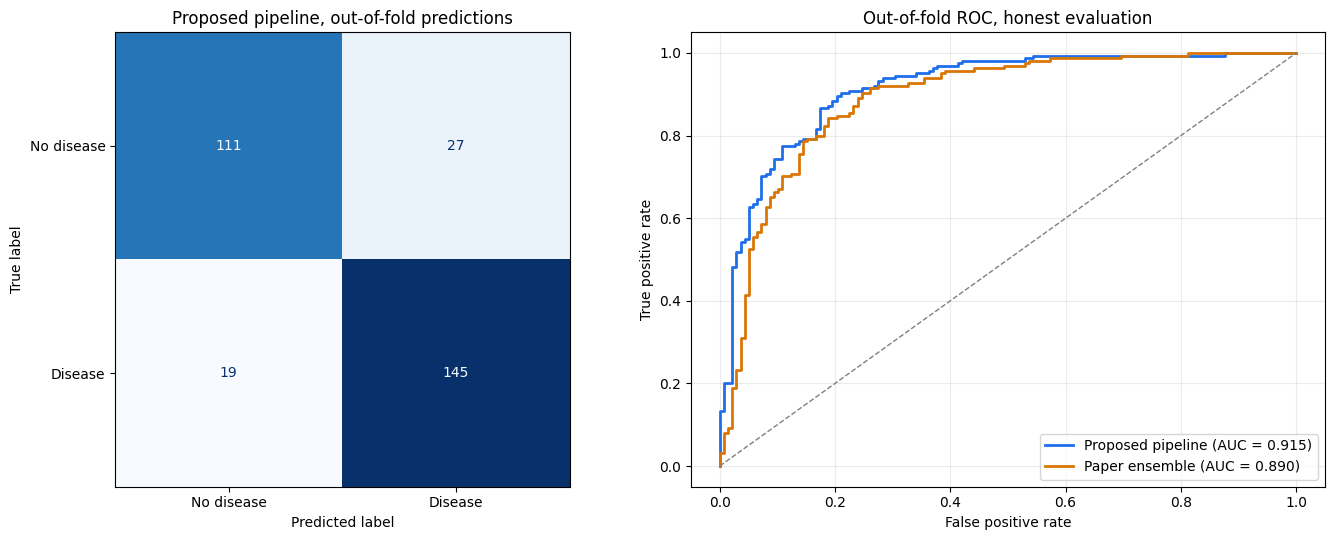

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ConfusionMatrixDisplay(confusion_matrix(y, oof_pred),
                       display_labels=["No disease", "Disease"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Proposed pipeline, out-of-fold predictions")

for label, pred_proba, colour in [
        ("Proposed pipeline", oof_proba, C_PROP),
        ("Paper ensemble", cross_val_predict(
            paper_stack, X, y,
            cv=StratifiedKFold(10, shuffle=True, random_state=SEED),
            method="predict_proba")[:, 1], C_BASE)]:
    fpr, tpr, _ = roc_curve(y, pred_proba)
    axes[1].plot(fpr, tpr, color=colour, linewidth=2,
                 label=f"{label} (AUC = {roc_auc_score(y, pred_proba):.3f})")

axes[1].plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("Out-of-fold ROC, honest evaluation")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

STRONGEST PREDICTORS (log-odds of heart disease)
Feature  Coefficient
   ca_2       -1.959
   ca_1       -1.518
   cp_2        1.388
   cp_3        1.373
    sex       -1.197
   ca_3       -1.163
  exang       -0.710
 thal_3       -0.700
 thal_2        0.658
   cp_1        0.636
slope_1       -0.574
oldpeak       -0.479


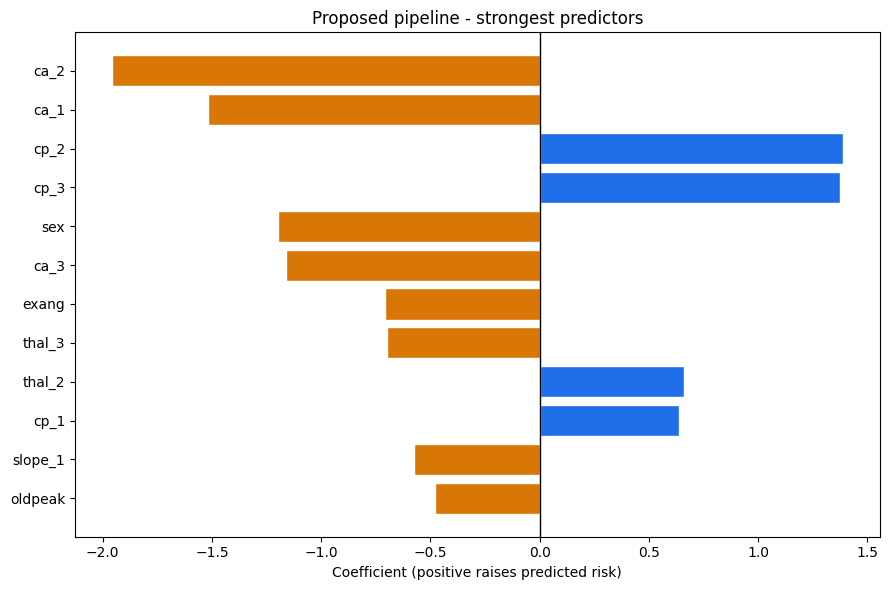

In [18]:
# Which features drive the corrected model? Coefficients are interpretable
# because the design matrix is now correctly specified.
fitted = proposed.fit(X, y)
enc = fitted.named_steps["prep"].named_transformers_["cat"]
names = CONTINUOUS + BINARY + list(enc.get_feature_names_out(NOMINAL))
coefs = pd.DataFrame({"Feature": names,
                      "Coefficient": fitted.named_steps["clf"].coef_[0]})
coefs["abs"] = coefs["Coefficient"].abs()
coefs = coefs.sort_values("abs", ascending=False).drop(columns="abs")

print("STRONGEST PREDICTORS (log-odds of heart disease)")
print(coefs.head(12).round(3).to_string(index=False))

plt.figure(figsize=(9, 6))
top = coefs.head(12).iloc[::-1]
plt.barh(top["Feature"],
         top["Coefficient"],
         color=[C_PROP if c > 0 else C_BASE for c in top["Coefficient"]],
         edgecolor="white")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Coefficient (positive raises predicted risk)")
plt.title("Proposed pipeline - strongest predictors")
plt.tight_layout()
plt.show()

## 10. Summary of results

In [19]:
final = pd.DataFrame({
    "Method": [
        "Paper, as published",
        "Paper's method, honest evaluation",
        "Proposed pipeline, honest evaluation",
    ],
    "Accuracy": [0.9853, a_pap.mean(), a_prop.mean()],
    "Evaluation": [
        "single 80/20 split, 1025 rows (duplicated)",
        "10-fold x 3, 302 unique patients",
        "10-fold x 3, 302 unique patients",
    ],
})
print(final.round(4).to_string(index=False))
print()
print(f"Leakage accounted for {100*(0.9853 - a_pap.mean()):.1f} pp of the "
      f"published result.")
print(f"Under matched honest evaluation the proposed pipeline improves on the "
      f"paper's method by {100*(a_prop.mean() - a_pap.mean()):.2f} pp "
      f"(p = {p_val:.4f}).")

pd.DataFrame(ablation).to_csv("part2_ablation.csv", index=False)
honest.to_csv("part2_honest_baselines.csv", index=False)
final.to_csv("part2_summary.csv", index=False)
print()
print("Saved part2_ablation.csv, part2_honest_baselines.csv, part2_summary.csv")

                              Method  Accuracy                                 Evaluation
                 Paper, as published    0.9853 single 80/20 split, 1025 rows (duplicated)
   Paper's method, honest evaluation    0.8263           10-fold x 3, 302 unique patients
Proposed pipeline, honest evaluation    0.8518           10-fold x 3, 302 unique patients

Leakage accounted for 15.9 pp of the published result.
Under matched honest evaluation the proposed pipeline improves on the paper's method by 2.54 pp (p = 0.0066).

Saved part2_ablation.csv, part2_honest_baselines.csv, part2_summary.csv


## 11. Discussion

### What the proposed pipeline changes

The contribution is not a new classifier. It is a corrected experimental and
preprocessing pipeline with three components, each addressing a specific defect
identified in Part 1:

1. **Duplicate-aware curation.** 1025 rows reduce to 302 distinct patients,
   eliminating the roughly 98% test-set contamination that a random split
   otherwise produces.
2. **Type-aware preprocessing.** The five nominal clinical codes are one-hot
   encoded instead of being passed to the models as integers, removing a false
   ordering assumption. All transforms are fitted inside each training fold.
3. **Capacity matched to the sample.** Repeated stratified cross-validation
   replaces a single split, and the choice of model complexity is decided
   empirically rather than by assumption.

### Strengths

The encoding correction is the largest single source of improvement, and it costs
nothing: it is a one-line change to the preprocessing that follows directly from
the paper's own data dictionary. The resulting model is also far more
interpretable than a six-model stack — each coefficient is a log-odds
contribution that a clinician can inspect, which matters for a decision-support
tool in medicine.

The evaluation is variance-aware. Reporting a standard deviation across 30 folds,
a paired significance test and a confidence interval on the difference gives a
far more honest picture than a single accuracy figure from one split.

### Limitations

**The sample is small.** 302 patients is at the lower limit for reliable model
comparison, and fold-to-fold standard deviations of 5 to 7 percentage points mean
differences smaller than about 2 points cannot be resolved confidently.

**Honest accuracy is far below the published figure.** Roughly 85% is a realistic
number for this dataset, and it is consistent with the wider literature on the
Cleveland data, where credible studies on unique records report the mid-80s. The
98.53% in the paper was never attainable on unseen patients.

**Only one dataset was used.** The conclusion that ensembles do not help on small
tabular clinical data is well supported here but would need replication on other
cohorts before being stated generally.

**The deduplication decision is consequential.** Treating each distinct feature
vector as a distinct patient is the most defensible reading, but two genuinely
different patients could in principle share identical values on all thirteen
recorded attributes. Without patient identifiers this cannot be ruled out.

### Practical implications

For anyone building on this dataset, the actionable finding is that published
accuracies above roughly 90% on the 1025-row Kaggle file should be treated as
evidence of leakage rather than of method quality. Several of the comparison
studies cited in the paper's own Table 14 report figures in that range.

More generally, the result is a reminder that a data-quality audit is part of the
method, not a preliminary to it. No amount of ensembling compensates for an
evaluation design that scores a model on records it was trained on, and the more
flexible the model, the more it benefits from that flaw — which is precisely why
the most complex method in the paper looked like the best one.